## 1. Import và cấu hình thực nghiệm

In [ ]:
from pathlib import Path
import sys, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Memory, dump
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
from joblib import Memory, dump, load

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/data.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.data import load_prepared_mnist
SEED, N_FOLDS = 42, 10
OUTPUT = ROOT / 'results' / 'stacking_adaboost'
OUTPUT.mkdir(parents=True, exist_ok=True)
memory = Memory(OUTPUT / 'cache', verbose=0)


## 2. Nạp dữ liệu

In [ ]:
X, y, X_test, y_test = load_prepared_mnist()
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=10000, stratify=y, random_state=SEED)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)
print(np.unique(y_train))
print(np.unique(y_test))


Train: (50000, 784) Validation: (10000, 784) Test: (10000, 784)


## 3. Khai báo SVM, KNN và MLP 1 lớp (512,)

In [ ]:
selection_dir = ROOT / 'results' / 'select_base_models'
base_models = load(selection_dir / 'selected_estimators.joblib')

display(pd.DataFrame({
    'model': list(base_models),
    'config': [str(model) for model in base_models.values()]
}))
display(pd.DataFrame({'model': list(base_models), 'config': [str(m) for m in base_models.values()]}))


,model,config
0,SVM,"SVC(C=10, cache_size=2000, probability=True, r..."
1,KNN,"KNeighborsClassifier(n_jobs=-1, n_neighbors=3,..."
2,MLP512,"MLPClassifier(alpha=0.01, batch_size=256, hidd..."


In [ ]:
print('Bộ ba dùng cho stacking:', list(base_models))
assert len(base_models) == 3

## 4. Tạo 30 đặc trưng OOF bằng StratifiedKFold 10-fold

In [4]:
@memory.cache
def fold_proba(estimator, X_fit, y_fit, X_holdout):
    model = clone(estimator).fit(X_fit, y_fit)
    return model.predict_proba(X_holdout)[:, np.argsort(model.classes_)]

names = list(base_models)
folds = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True,
                           random_state=SEED).split(X_train, y_train))
Z_train = np.zeros((len(y_train), 10 * len(names)), dtype=np.float32)

t0 = time.perf_counter()
for j, name in enumerate(names):
    for fold, (fit, hold) in enumerate(folds, 1):
        Z_train[hold, 10*j:10*(j+1)] = fold_proba(
            base_models[name], X_train[fit], y_train[fit], X_train[hold])
        print(f'{name}: fold {fold}/{N_FOLDS}', flush=True)
oof_seconds = time.perf_counter() - t0
print('OOF:', Z_train.shape, f'— {oof_seconds:.1f}s')
# Mỗi ảnh nhận xác suất từ model chưa học ảnh đó. Không fit meta bằng dự đoán in-sample.
# Cache giúp chạy lại tiếp các fold đã xong; thời gian khi có cache không phải thời gian train mới.


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: fold 1/10


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: fold 2/10


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM: fold 3/10


... (27 outputs left out)

MLP512: fold 8/10
MLP512: fold 9/10


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP512: fold 10/10
OOF: (50000, 30) — 19435.9s


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


## 5. Refit model nền trên toàn bộ train và tạo đặc trưng validation

In [5]:
@memory.cache
def fit_base(estimator, X, y):
    return clone(estimator).fit(X, y)

def predict_base(model, X, name):
    proba = model.predict_proba(X)
    pred = model.predict(X) if name == 'SVM' else model.classes_[proba.argmax(1)]
    return proba[:, np.argsort(model.classes_)], pred

fitted, val_proba, val_pred, base_times = {}, {}, {}, []

for name, estimator in base_models.items():
    t0 = time.perf_counter()
    model = fitted[name] = fit_base(estimator, X_train, y_train)
    fit_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    val_proba[name], val_pred[name] = predict_base(model, X_val, name)
    predict_seconds = time.perf_counter() - t0

    base_times.append(dict(
        model=name, fit_or_cache_seconds=fit_seconds,
        val_proba_and_predict_seconds=predict_seconds))
    print('Refit hoàn tất:', name, flush=True)

Z_val = np.concatenate([val_proba[name] for name in names], axis=1)


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Refit hoàn tất: SVM
Refit hoàn tất: KNN
Refit hoàn tất: MLP512


d:\midterm_pattern_recognition\mnist-pattern-recognition\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.
  warnings.warn(


## 6. Huấn luyện AdaBoost trên đặc trưng OOF

In [24]:
params = dict(n_estimators=100, learning_rate=0.5, random_state=SEED)
key = 'estimator' if 'estimator' in inspect.signature(AdaBoostClassifier).parameters else 'base_estimator'
params[key] = DecisionTreeClassifier(max_depth=2, random_state=SEED)
if 'algorithm' in inspect.signature(AdaBoostClassifier).parameters:
    params['algorithm'] = 'SAMME'
meta = AdaBoostClassifier(**params)


tree_key = key
def make_meta(lr=0.5, depth=2, trees=100):
    return clone(meta).set_params(
        learning_rate=lr, n_estimators=trees,
        **{tree_key: DecisionTreeClassifier(max_depth=depth, random_state=SEED)})

def score_row(pred, lr, depth, trees):
    _, _, f1, _ = precision_recall_fscore_support(
        y_val, pred, average='macro', zero_division=0)
    return dict(learning_rate=lr, max_depth=depth, n_estimators=trees,
                accuracy=accuracy_score(y_val, pred), f1_macro=f1)

voting_acc = accuracy_score(y_val, np.mean(
    [val_proba[name] for name in names], axis=0).argmax(1))

def show_results(table, parameter):
    display(table.round(5))
    ax = table.plot(x=parameter, y=['accuracy', 'f1_macro'], marker='o')
    ax.axhline(voting_acc, color='gray', linestyle='--', label='Soft voting accuracy')
    ax.set_ylabel('Validation score')
    ax.legend()
    plt.tight_layout()
    plt.savefig(OUTPUT / f'survey_{parameter}.png', dpi=180)
    plt.show()


### 6.1. Khảo sát learning rate

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
0,0.01,2,100,0.8929,0.85311
1,0.10,2,100,0.9830,0.98299
2,0.20,2,100,0.9851,0.98503
3,0.50,2,100,0.9820,0.98190
4,1.00,2,100,0.9811,0.98095


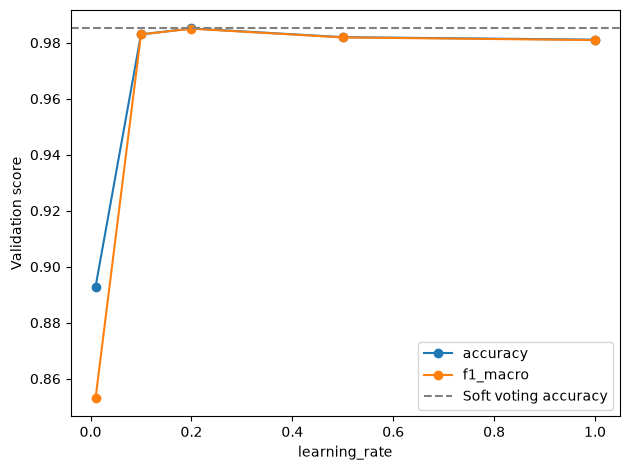

In [25]:
lr_rows = []
for lr in [0.01, 0.1, 0.2, 0.5, 1.0]:
    model = make_meta(lr=lr).fit(Z_train, y_train)
    lr_rows.append(score_row(model.predict(Z_val), lr, 2, 100))
lr_results = pd.DataFrame(lr_rows)
show_results(lr_results, 'learning_rate')

### 6.2. Khảo sát độ sâu cây

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
0,0.5,1,100,0.9844,0.98433
1,0.5,2,100,0.9820,0.98190
2,0.5,3,100,0.9840,0.98391
3,0.5,4,100,0.9830,0.98291


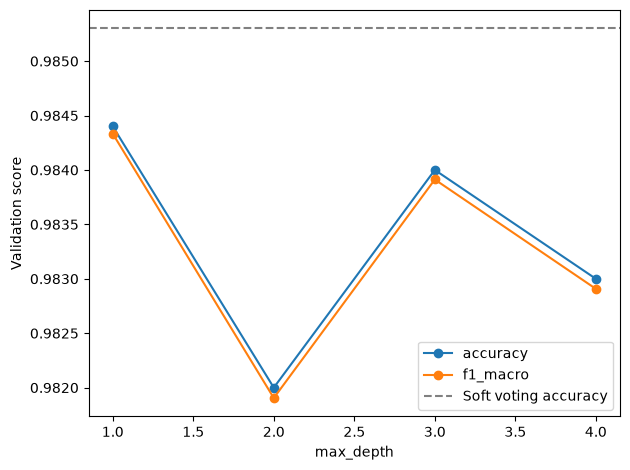

In [27]:
depth_rows = []
for depth in [1, 2, 3, 4]:
    model = make_meta(lr=0.5, depth=depth, trees=100).fit(Z_train, y_train)
    depth_rows.append(score_row(model.predict(Z_val), 0.5, depth, 100))

depth_results = pd.DataFrame(depth_rows)
show_results(depth_results, 'max_depth')

### 6.3. Khảo sát số cây

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
0,0.5,2,1,0.3152,0.22027
1,0.5,2,20,0.9841,0.98405
2,0.5,2,50,0.9836,0.98351
3,0.5,2,100,0.9820,0.98190
4,0.5,2,200,0.9820,0.98190
5,0.5,2,300,0.9812,0.98109


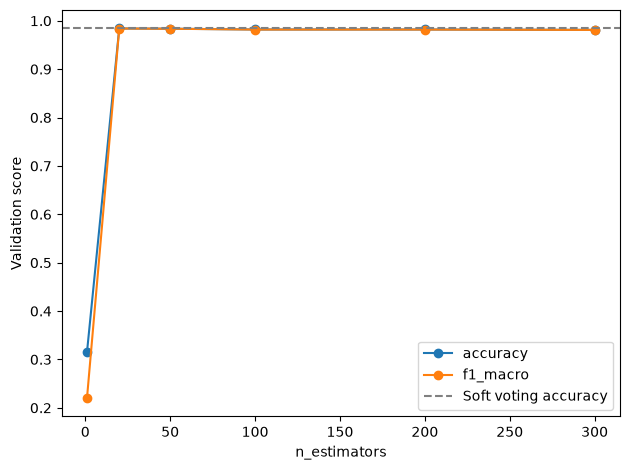

In [28]:
tree_counts = [1, 20, 50, 100, 200, 300]
model = make_meta(trees=300).fit(Z_train, y_train)
tree_rows = []
for trees, pred in enumerate(model.staged_predict(Z_val), 1):
    if trees in tree_counts:
        tree_rows.append(score_row(pred, 0.5, 2, trees))
tree_results = pd.DataFrame(tree_rows)
show_results(tree_results, 'n_estimators')

### 6.4. Chọn cấu hình bằng validation và huấn luyện cuối

In [29]:
survey = pd.concat([lr_results, depth_results, tree_results], ignore_index=True)
survey = survey.drop_duplicates(['learning_rate', 'max_depth', 'n_estimators'])
ranked = survey.sort_values(
    ['accuracy', 'f1_macro', 'max_depth', 'n_estimators', 'learning_rate'],
    ascending=[False, False, True, True, True])
display(ranked.round(5))
best = ranked.iloc[0]
meta = make_meta(float(best.learning_rate), int(best.max_depth), int(best.n_estimators))
t0 = time.perf_counter()
meta.fit(Z_train, y_train)
meta_seconds = time.perf_counter() - t0
survey.to_csv(OUTPUT / 'hyperparameters.csv', index=False)
ranked.head(1).to_csv(OUTPUT / 'selected_config.csv', index=False)
print('Cấu hình cuối:', meta)

,learning_rate,max_depth,n_estimators,accuracy,f1_macro
2,0.20,2,100,0.9851,0.98503
5,0.50,1,100,0.9844,0.98433
10,0.50,2,20,0.9841,0.98405
7,0.50,3,100,0.9840,0.98391
11,0.50,2,50,0.9836,0.98351
1,0.10,2,100,0.9830,0.98299
8,0.50,4,100,0.9830,0.98291
3,0.50,2,100,0.9820,0.98190
13,0.50,2,200,0.9820,0.98190
14,0.50,2,300,0.9812,0.98109


Cấu hình cuối: AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2,
                                                    random_state=42),
                   learning_rate=0.2, n_estimators=100, random_state=42)


## 7. So sánh trên validation trước khi đánh giá test

In [30]:
def evaluate(y, predictions, split):
    rows = []
    for name, pred in predictions.items():
        precision, recall, f1, _ = precision_recall_fscore_support(
            y, pred, average='macro', zero_division=0)
        rows.append(dict(split=split, model=name, accuracy=accuracy_score(y, pred),
            precision_macro=precision, recall_macro=recall, f1_macro=f1))
    return pd.DataFrame(rows)

val_pred['Soft voting'] = np.mean(list(val_proba.values()), axis=0).argmax(1)
val_pred['Stacking AdaBoost'] = meta.predict(Z_val)
val_results = evaluate(y_val, val_pred, 'Validation')
display(val_results.round(5))
# Bộ ba đã được chọn bằng validation nên điểm này có thể lạc quan.
# Cấu hình meta cố định; không mặc định stacking phải vượt voting hoặc model đơn.
train_proba, train_pred = {}, {}
for name in names:
    train_proba[name], train_pred[name] = predict_base(fitted[name], X_train, name)
train_pred['Soft voting'] = np.mean(list(train_proba.values()), axis=0).argmax(1)
train_pred['Stacking AdaBoost'] = meta.predict(np.concatenate(list(train_proba.values()), axis=1))
train_results = evaluate(y_train, train_pred, 'Train (in-sample)')
display(train_results.round(5))

,split,model,accuracy,precision_macro,recall_macro,f1_macro
0,Validation,SVM,0.9826,0.98254,0.98251,0.98251
1,Validation,KNN,0.9720,0.97255,0.97163,0.97196
2,Validation,MLP512,0.9828,0.98271,0.98271,0.98269
3,Validation,Soft voting,0.9853,0.98538,0.98520,0.98528
4,Validation,Stacking AdaBoost,0.9851,0.98506,0.98501,0.98503


,split,model,accuracy,precision_macro,recall_macro,f1_macro
0,Train (in-sample),SVM,0.99990,0.99990,0.99990,0.99990
1,Train (in-sample),KNN,1.00000,1.00000,1.00000,1.00000
2,Train (in-sample),MLP512,1.00000,1.00000,1.00000,1.00000
3,Train (in-sample),Soft voting,1.00000,1.00000,1.00000,1.00000
4,Train (in-sample),Stacking AdaBoost,0.99998,0.99998,0.99998,0.99998


## 8. Đánh giá cuối trên test và confusion matrix

,split,model,accuracy,precision_macro,recall_macro,f1_macro
0,Test,Stacking AdaBoost,0.9846,0.98464,0.98447,0.98455
1,Test,SVM,0.9833,0.98336,0.98320,0.98327
2,Test,KNN,0.9700,0.97024,0.96962,0.96983
3,Test,MLP512,0.9835,0.98347,0.98339,0.98343
4,Test,Soft voting,0.9854,0.98554,0.98534,0.98543


,model,proba_seconds
0,SVM,60.525
1,KNN,7.243
2,MLP512,0.182


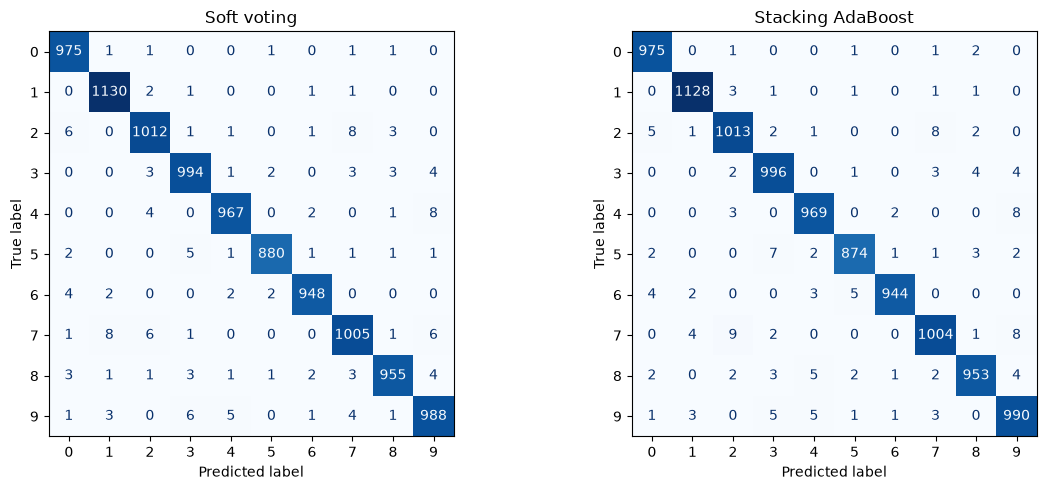

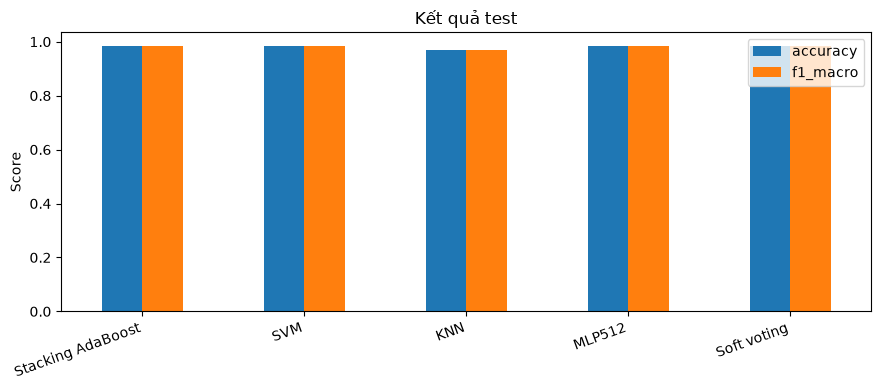

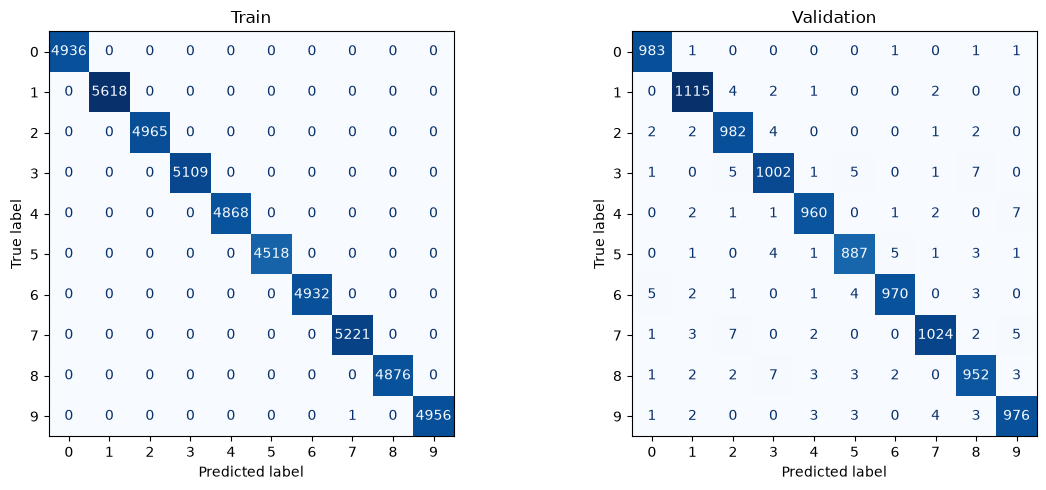

In [31]:
test_proba, test_pred, predict_times = {}, {}, []

start = time.perf_counter()
for name, model in fitted.items():
    t0 = time.perf_counter()
    test_proba[name] = model.predict_proba(X_test)[:, np.argsort(model.classes_)]
    predict_times.append(dict(model=name, proba_seconds=time.perf_counter()-t0))
t0 = time.perf_counter()
Z_test = np.concatenate([test_proba[name] for name in names], axis=1)
test_pred['Stacking AdaBoost'] = meta.predict(Z_test)
end = time.perf_counter()
stacking_extra_seconds = end - t0
stacking_total_seconds = end - start
for name in names:
    test_pred[name] = fitted[name].predict(X_test) if name == 'SVM' else test_proba[name].argmax(1)

t0 = time.perf_counter()
test_pred['Soft voting'] = np.mean(
    [test_proba[name] for name in names], axis=0).argmax(1)
voting_extra_seconds = time.perf_counter() - t0

test_results = evaluate(y_test, test_pred, 'Test')
display(test_results.round(5))
display(pd.DataFrame(predict_times).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ['Soft voting', 'Stacking AdaBoost']):
    ConfusionMatrixDisplay.from_predictions(y_test, test_pred[name], labels=np.arange(10),
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout(); fig.savefig(OUTPUT / 'confusion_test.png', dpi=180)
plt.show()
ax = test_results.set_index('model')[['accuracy', 'f1_macro']].plot.bar(figsize=(9, 4))
ax.set(ylabel='Score', xlabel='', title='Kết quả test')
plt.xticks(rotation=20, ha='right'); plt.tight_layout()
plt.savefig(OUTPUT / 'comparison_test.png', dpi=180); plt.show()
# Không thay nhóm hoặc tham số dựa vào bảng test này.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (label, target, preds) in zip(axes, [('Train', y_train, train_pred), ('Validation', y_val, val_pred)]):
    ConfusionMatrixDisplay.from_predictions(target, preds['Stacking AdaBoost'], ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(label)
plt.tight_layout(); plt.savefig(OUTPUT / 'stacking_train_val.png'); plt.show()



## 9. Lưu bộ phân lớp và kết quả báo cáo

In [32]:
results = pd.concat([train_results, val_results, test_results], ignore_index=True)
results.to_csv(OUTPUT / 'metrics.csv', index=False)
pd.DataFrame(base_times).to_csv(OUTPUT / 'base_times.csv', index=False)
pd.DataFrame([dict(oof_or_cache_seconds=oof_seconds, meta_fit_seconds=meta_seconds)]).to_csv(
    OUTPUT / 'stacking_times.csv', index=False)
pd.DataFrame(predict_times).to_csv(
    OUTPUT / 'test_prediction_times.csv', index=False)

pd.DataFrame([dict(
    stacking_total_seconds=stacking_total_seconds, stacking_extra_seconds=stacking_extra_seconds,
    voting_extra_seconds=voting_extra_seconds
)]).to_csv(OUTPUT / 'aggregation_times.csv', index=False)
np.savez_compressed(OUTPUT / 'meta_features.npz', Z_train=Z_train, y_train=y_train)
dump(dict(base_models=fitted, meta_model=meta, model_order=names,
          classes=np.arange(10), seed=SEED, folds=N_FOLDS), OUTPUT / 'classifier.joblib')
print('Đã lưu bộ phân lớp và kết quả:', OUTPUT)
# Suy luận: base.predict_proba → ghép đúng model_order và classes → meta.predict.
# Chỉ nạp file joblib do chính bạn tạo hoặc từ nguồn tin cậy.


Đã lưu bộ phân lớp và kết quả: d:\midterm_pattern_recognition\mnist-pattern-recognition\results\stacking_adaboost
